In [ ]:

import numpy as np
import matplotlib.pyplot as plt

import salvus.namespace as sn

import salvus.mesh
import salvus.mesh.layered_meshing as lm
from salvus.material._details import material as md
from my_code.utilities import *
from pathlib import Path
from material_ela_constants.Elastic_Material import * 
from salvus.toolbox.helpers.wavefield_output import (
    WavefieldOutput,
    wavefield_output_to_xarray,
)


def oriented_material(material_unoriented, angle_in_degrees):
    """Rotate a hexagonal material and convert it to the 2D solver form (C11..C33)."""
    # Defined here, not imported: importing FWI_orientation_single_layer runs its whole FWI.
    orientation = sn.material.orientation.ClockwiseAngle.from_params(
        angle_in_degrees=angle_in_degrees
    )
    return md.to_solver_form(material_unoriented.with_orientation(orientation), ndim=2)


# Directories in WSL
PROJECT_DIR = '/home/oliver/workspace/Salvus/elastic_model/anisotropic/Project'
IMAGE_DIR = '/home/oliver/workspace/Salvus/elastic_model/anisotropic/image'
DATA_DIR = '/home/oliver/workspace/Salvus/elastic_model/anisotropic/data'


# Directories in Windows
PROJECT_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/Project'
DATA_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/data'
IMAGE_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/image'


# create dir if it does not exist
Path(IMAGE_DIR).mkdir(parents=True, exist_ok=True)
Path(DATA_DIR).mkdir(parents=True, exist_ok=True)
Path(IMAGE_DIR_WIN).mkdir(parents=True, exist_ok=True)
Path(DATA_DIR_WIN).mkdir(parents=True, exist_ok=True)



# salvus site 
SITE_NAME = "oliver_wsl"
RANKS = 8


# center frequency 
CENTRAL_FREQUENCY = 1e6 
f_c = CENTRAL_FREQUENCY
# dt = 1 / (250 f_c) = 4 ns stays below the mesh CFL limit (~4.25 ns for this mesh)
sampling_rate_in_hertz = CENTRAL_FREQUENCY * 250
time_step_in_seconds = 1/sampling_rate_in_hertz
end_time = 6e-6                     # simulation end time [s]

amplitude_ratio = 1e10              # source amplitude (fy of VectorPoint2D)


n_rxs = 1
n_txs = 1


x0, x1 = 0.0, 0.01
y0, y1 = 0.0, 0.01



# material properties
matl = Austenite()
VP_0deg = np.sqrt(matl.C33 / matl.RHO)
VP_90deg = np.sqrt(matl.C11 / matl.RHO)

STIFFNESS_PARAMETERS = {'C11', 'C12', 'C13', 'C22', 'C23', 'C33'}   # Salvus 2D Voigt names

# ---- Mesh resolution ----------------------------------------------------
elements_per_wavelength = 4
model_order             = 4
ab_reference_velocity   = VP_0deg
number_of_wavelengths   = 2
reference_frequency     = CENTRAL_FREQUENCY * 2
free_surfaces           = ['y0', 'y1']


smoothing = 0

# project name (folder's name)
PROJECT_NAME = fr"tomography_solid_orientation_multilayer"



# =============================================================================
# Project, true model and mesh
# =============================================================================

domain = sn.domain.dim2.BoxDomain(x0=x0, x1=x1, y0=y0, y1=y1)

p = sn.Project.from_domain(
    path=Path(PROJECT_DIR_WIN, PROJECT_NAME), domain=domain, load_if_exists=True
)

# Unrotated hexagonal material built from the austenite constants
material_unoriented = sn.material.elastic.hexagonal.TensorComponents.from_params(
    **matl.VTI_parameters()
)

BACKGROUND_ANGLE_DEG = 45.0
LAYER1_ANGLE_DEG = 70.0
LAYER2_ANGLE_DEG = 30.0
LAYER3_ANGLE_DEG = 60.0
LAYER4_ANGLE_DEG = 20.0
LAYER5_ANGLE_DEG = 40.0

matl_background = oriented_material(material_unoriented, BACKGROUND_ANGLE_DEG)
matl_layer_1      = oriented_material(material_unoriented, LAYER1_ANGLE_DEG)
matl_layer_2      = oriented_material(material_unoriented, LAYER2_ANGLE_DEG)
matl_layer_3      = oriented_material(material_unoriented, LAYER3_ANGLE_DEG)
matl_layer_4      = oriented_material(material_unoriented, LAYER4_ANGLE_DEG)
matl_layer_5      = oriented_material(material_unoriented, LAYER5_ANGLE_DEG)

# Layers listed top to bottom: background / layers 1-5 / background
m_true = lm.LayeredModel(
    [
        matl_background,
        sn.layered_meshing.interface.Hyperplane.at(0.009),
        matl_layer_1,
        sn.layered_meshing.interface.Hyperplane.at(0.007),
        matl_layer_2,
        sn.layered_meshing.interface.Hyperplane.at(0.006),
        matl_layer_3,
        sn.layered_meshing.interface.Hyperplane.at(0.0045),
        matl_layer_4,
        sn.layered_meshing.interface.Hyperplane.at(0.002),
        matl_layer_5,
        sn.layered_meshing.interface.Hyperplane.at(0.001),
        matl_background,
    ]
)

ab_params = salvus.mesh.simple_mesh.basic_mesh.AbsorbingBoundaryParameters(
    free_surface=free_surfaces,
    number_of_wavelengths=number_of_wavelengths,
    reference_velocity=ab_reference_velocity,
    reference_frequency=reference_frequency,
)

mesh_res = sn.MeshResolution(
    reference_frequency=reference_frequency,
    elements_per_wavelength=elements_per_wavelength,
    model_order=model_order,
)

# True (layered) model
mesh = lm.mesh_from_domain(
    domain=domain,
    model=sn.layered_meshing.MeshingProtocol(m_true, ab=ab_params),
    mesh_resolution=mesh_res,
)

# Starting model: same mesh, homogeneous background orientation everywhere
mesh_init = mesh.copy()
for k in STIFFNESS_PARAMETERS:
    mesh_init.element_nodal_fields[k][:] = getattr(matl_background, k).p


# =============================================================================
# Sources, receivers and events
# =============================================================================

tx_locations = np.array([[0.005, 0.01]])   # source (x, y) [m], one row per source
r_loc_all    = np.array([[x, 0.0 ] for x in np.linspace(0.001, 0.009, 9)])   # receiver (x, y) [m], shared by all events

receivers = [
    sn.simple_config.receiver.cartesian.Point2D(
        x=r[0], y=r[1], station_code=f"R{j+1}", fields=["displacement"]
    )
    for j, r in enumerate(r_loc_all)
]

# One event per source, each recorded by all receivers
event_ls = []
for i, s in enumerate(tx_locations):
    event_name = f"src_{i+1}"
    source = sn.simple_config.source.cartesian.VectorPoint2D(
        x=s[0], y=s[1], fx=0, fy=amplitude_ratio
    )
    p.add_to_project(
        sn.Event(event_name=event_name, sources=source, receivers=receivers)
    )
    event_ls.append(event_name)
print(f"{len(event_ls)} event(s) registered: {event_ls}")




Accordion()

1 event(s) registered: ['src_1']


In [20]:
r_loc_all    = np.array([[x, 0.0 ] for x in np.linspace(0.001, 0.009, 9)])   # receiver (x, y) [m], shared by all events
r_loc_all

array([[0.001, 0.   ],
       [0.002, 0.   ],
       [0.003, 0.   ],
       [0.004, 0.   ],
       [0.005, 0.   ],
       [0.006, 0.   ],
       [0.007, 0.   ],
       [0.008, 0.   ],
       [0.009, 0.   ]])

In [12]:
mesh

In [13]:
def forward_simulation(simulation_name, events,
                       fields=None, sampling_interval_in_time_steps=10):
    _n_events = 1 if isinstance(events, str) else len(events)
    print(f"  [forward_simulation] launching '{simulation_name}' "
          f"for {_n_events} event(s), volume_output={'yes' if fields else 'no'} ...")
    if fields:
        p.simulations.launch(
            ranks_per_job=RANKS,
            site_name=SITE_NAME,
            events=events,
            simulation_configuration=simulation_name,
            extra_output_configuration={
                "volume_data": {
                    "sampling_interval_in_time_steps": sampling_interval_in_time_steps,
                    "fields": fields,
                },
            },
            delete_conflicting_previous_results=True,
        )
    else:
        p.simulations.launch(
            ranks_per_job=RANKS,
            site_name=SITE_NAME,
            events=events,
            simulation_configuration=simulation_name,
            delete_conflicting_previous_results=True,
        )

    p.simulations.query(block=True, verbosity=-1)
    print(f"  [forward_simulation] '{simulation_name}' finished.")


def extract_data(simulation, events, receiver_field='displacement', field=None):
    ed = p.waveforms.get(data_name=simulation, events=events)[0]
    data = ed.get_waveform_data_xarray(receiver_field=receiver_field)
    wavefield = None
    if field:
        wavefield = wavefield_output_to_xarray(
            ed.get_wavefield_output(output_type='volume', field=field),
            p.simulations.get_mesh(simulation).points,
        ).T
    return data, wavefield


In [14]:
# forward simulation in the true multilayer model
SIMULATION_NAME = "forward_simulation"

# Ricker peaks at t = 0 -> start 1.5 periods early; snap start/end to the dt grid
start_time = -np.ceil(1.5 / f_c / time_step_in_seconds) * time_step_in_seconds
end_time   = np.round(end_time / time_step_in_seconds) * time_step_in_seconds

event_config = sn.EventConfiguration(
    wavelet=sn.simple_config.stf.Ricker(center_frequency=f_c),
    waveform_simulation_configuration=sn.WaveformSimulationConfiguration(
        start_time_in_seconds=start_time,
        end_time_in_seconds=end_time,
        time_step_in_seconds=time_step_in_seconds,
    ),
)

p.add_to_project(
    sn.UnstructuredMeshSimulationConfiguration(
        unstructured_mesh=mesh, name=SIMULATION_NAME, event_configuration=event_config,
    ),
    overwrite=True,
)

forward_simulation(SIMULATION_NAME, event_ls, fields=['displacement'])

  [forward_simulation] launching 'forward_simulation' for 1 event(s), volume_output=yes ...
[2026-10-27 11:42:15,701] INFO: Submitting job ...
Uploading 1 files...

🚀  Submitted job_2610271142925395_80a0d44946@oliver_wsl


VBox()

  [forward_simulation] 'forward_simulation' finished.


In [15]:
# extract the waveforms and wavefields for all events in the simulation
SIMULATION_NAME = "forward_simulation"
event_ls = p.events.list()          # all events registered in the project, e.g. ['src_1']

# receiver_data[event] : xarray (trace, time); traces = (receiver_id, component X/Y)
# wavefields[event]    : xarray (point, c, t); volume displacement at mesh points
receiver_data, wavefields = {}, {}
for event_name in event_ls:
    receiver_data[event_name], wavefields[event_name] = extract_data(
        SIMULATION_NAME, event_name, receiver_field='displacement', field='displacement'
    )
    print(f"{event_name}: receiver data {dict(receiver_data[event_name].sizes)}, "
          f"wavefield {dict(wavefields[event_name].sizes)}")

# time axis of the receiver data [s]
t = receiver_data[event_ls[0]].time.values

Finding enclosing elements (pass 1 of auto):   0%|          | 0/41877 [00:00<?, ?it/s]

Extracting wavefield to regular grid:   0%|          | 0/16 [00:00<?, ?it/s]

src_1: receiver data {'trace': 2, 'time': 1876}, wavefield {'point': 41877, 'c': 2, 't': 189}


In [16]:
receiver_data['src_1']

<xarray.DataArray 'displacement' (trace: 2, time: 1876)> Size: 15kB
array([[ 0.        ,  0.        ,  0.        , ..., -0.00169499,
        -0.00166033, -0.00162449],
       [ 0.        ,  0.        ,  0.        , ..., -0.00208562,
        -0.0020856 , -0.00208471]], shape=(2, 1876), dtype=float32)
Coordinates:
  * trace        (trace) object 16B MultiIndex
  * receiver_id  (trace) <U6 48B 'XX.R1.' 'XX.R1.'
  * component    (trace) <U1 8B 'X' 'Y'
  * time         (time) float64 15kB -1.5e-06 -1.496e-06 ... 5.996e-06 6e-06
Attributes:
    start_time_in_seconds:               -1.5e-06
    sampling_rate_in_hertz:              249999999.99999997
    start_time_in_seconds_utc_datetime:  1969-12-31T23:59:59.999998Z
    end_time_in_seconds_utc_datetime:    1970-01-01T00:00:00.000006Z
    reference_time_utc:                  1970-01-01T00:00:00.000000Z
    reference_time_in_seconds:           0.0
    npts:                                1876
    location:                            [[0.005 0.   ]]

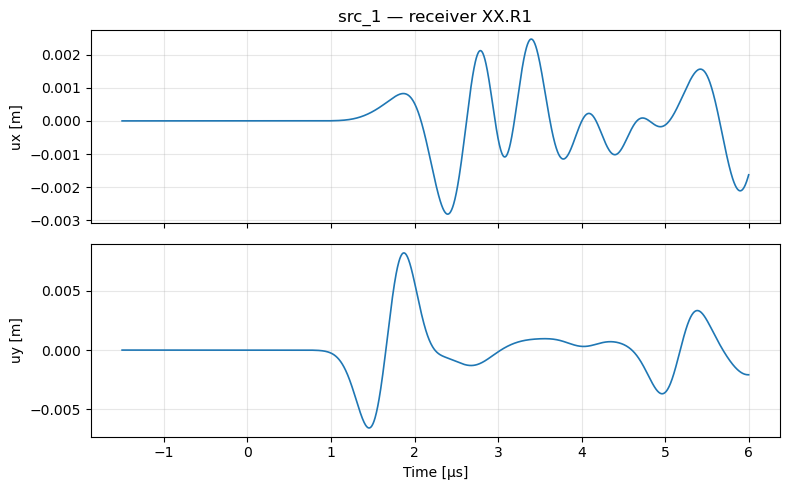

In [18]:
# plot X and Y displacement at each receiver in the time domain
for event_name in event_ls:
    data = receiver_data[event_name]
    for rec_id in np.unique(data.receiver_id.values):
        rec = data.sel(receiver_id=rec_id)

        fig, axes = plt.subplots(2, 1, figsize=(8, 5), dpi=100, sharex=True)
        for ax, comp in zip(axes, ['X', 'Y']):
            ax.plot(rec.time.values * 1e6, rec.sel(component=comp).values.squeeze(), lw=1.2)
            ax.set_ylabel(f'u{comp.lower()} [m]')
            ax.grid(alpha=0.3)
        axes[-1].set_xlabel('Time [µs]')
        axes[0].set_title(f'{event_name} — receiver {rec_id.strip(".")}')
        plt.tight_layout()
        plt.show()

